In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import minimize

FMS = ["Chronos-2-full", "TimesFM-2.5", "TiRex", "FlowState"]
SETS = {"Volatilität": ("binance_1h_neu", "qlike"),
        "Volatilität BTC/ETH/SOL": ("binance_1h", "qlike"),
        "Strom": ("strom_1h", "ape")}
EVAL_START, EVAL_END = "2025-11-01", "2026-03-01"


def loss(kind, y, f):
    r = y / f
    return r - np.log(r) - 1 if kind == "qlike" else np.abs(y - f) / y


rows = []
for domain, (ds, kind) in SETS.items():
    files = [p for p in (Path("results/forecasts") / ds).glob("*__*.parquet") if p.stem.split("__")[1] in FMS]
    if not files:
        print("fehlt:", ds); continue
    fc = pd.concat([pd.read_parquet(p) for p in files])
    fc = fc[(fc["target_date"] >= EVAL_START) & (fc["target_date"] < EVAL_END)]
    for (sid, h), g in fc.groupby(["sid", "h"]):
        M = g.pivot_table(index="origin", columns="model", values="mean").dropna()
        y = g.groupby("origin")["y"].first().reindex(M.index).to_numpy()
        F = M.to_numpy()
        C = np.corrcoef(np.log(y[:, None] / F).T)
        best = loss(kind, y[:, None], F).mean(0).min()
        obj = lambda z: loss(kind, y, F @ (np.exp(z) / np.exp(z).sum())).mean()
        z = minimize(obj, np.zeros(F.shape[1]), method="Nelder-Mead", options={"maxiter": 4000}).x
        rows.append({"Domäne": domain, "Serie": sid, "h": h, "FMs": F.shape[1],
                     "Korrelation": C[np.triu_indices_from(C, 1)].mean(),
                     "Verbesserung %": -100 * (obj(z) / best - 1)})

pts = pd.DataFrame(rows)
display(pts.round(3))
print("Rangkorrelation Korrelation vs. Verbesserung:", round(pts["Korrelation"].corr(pts["Verbesserung %"], method="spearman"), 2))

,Domäne,Serie,h,FMs,Korrelation,Verbesserung %
0,Volatilität,BNBUSDT,1,4,0.974,0.507
1,Volatilität,BNBUSDT,24,4,0.933,0.922
2,Volatilität,EURUSDT,1,4,0.976,0.486
3,Volatilität,EURUSDT,24,4,0.975,0.703
4,Volatilität,PAXGUSDT,1,4,0.961,1.160
5,Volatilität,PAXGUSDT,24,4,0.944,0.000
6,Volatilität,XRPUSDT,1,4,0.969,0.555
7,Volatilität,XRPUSDT,24,4,0.954,1.741
8,Volatilität BTC/ETH/SOL,BTCUSDT,1,2,0.964,0.230
9,Volatilität BTC/ETH/SOL,BTCUSDT,24,2,0.949,0.966


Rangkorrelation Korrelation vs. Verbesserung: -0.76


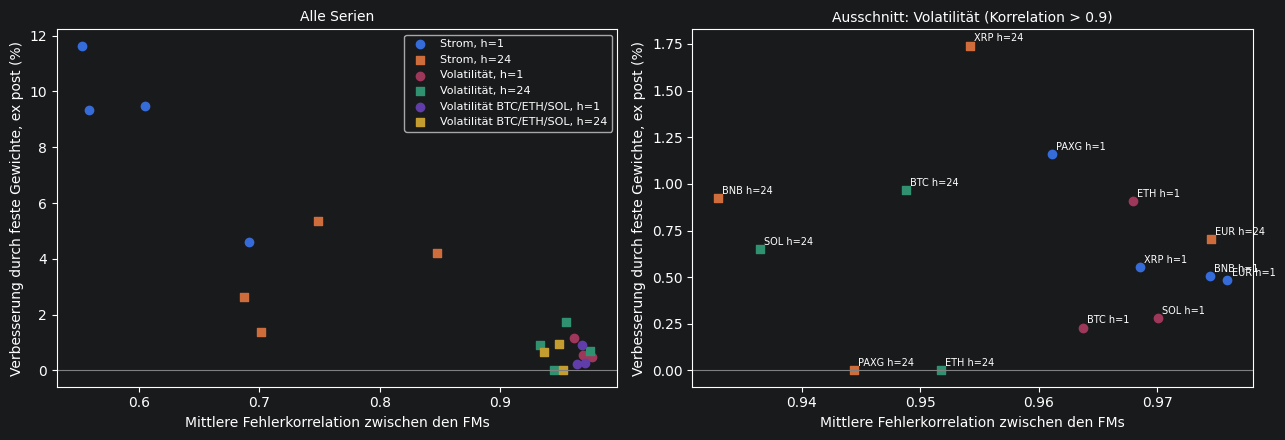

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
zoom = pts[pts["Korrelation"] > 0.9]

for ax, data in [(ax1, pts), (ax2, zoom)]:
    for (dom, h), d in data.groupby(["Domäne", "h"]):
        ax.scatter(d["Korrelation"], d["Verbesserung %"], marker="o" if h == 1 else "s", label=f"{dom}, h={h}")
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xlabel("Mittlere Fehlerkorrelation zwischen den FMs")
    ax.set_ylabel("Verbesserung durch feste Gewichte, ex post (%)")

for _, r in zoom.iterrows():                       # Serien im Zoom beschriften
    ax2.annotate(f'{r["Serie"].replace("USDT", "")} h={r["h"]}', (r["Korrelation"], r["Verbesserung %"]),
                 fontsize=7, xytext=(3, 3), textcoords="offset points")

ax1.set_title("Alle Serien", fontsize=10)
ax2.set_title("Ausschnitt: Volatilität (Korrelation > 0.9)", fontsize=10)
ax1.legend(fontsize=8)
plt.tight_layout()
fig.savefig("results/korrelation_vs_gewinn.png", dpi=200)
plt.show()

The chart shows that combination of FMs is more useful the less correlation among the FMs.

In [4]:
OOS = {"Volatilität": ("06_res.parquet", "qlike"), "Strom": ("07_res.parquet", "ape")}
METH = ["Statisch", "Gate linear", "Gate MLP"]

rows = []
for domain, (fname, kind) in OOS.items():
    r = pd.read_parquet(Path("results/forecasts") / fname)
    r = r[r["pool"] == "4 FMs"].copy()                       # gleicher Pool wie die Obergrenze
    r["l"] = loss(kind, r["y"].to_numpy(), r["mean"].to_numpy())
    for (sid, h), g in r.groupby(["sid", "h"]):
        Lm = g.groupby("model")["l"].mean()
        best = Lm[[m for m in FMS if m in Lm]].min()          # bestes einzelnes FM, ex post
        for m in METH:
            rows.append({"Domäne": domain, "Serie": sid, "h": h, "Methode": m,
                         "OOS %": -100 * (Lm[m] / best - 1)})

oos = pd.DataFrame(rows)
cmp = oos.merge(pts[["Domäne", "Serie", "h", "Korrelation", "Verbesserung %"]], on=["Domäne", "Serie", "h"])
display(cmp.pivot_table(index=["Domäne", "Serie", "h"], columns="Methode", values="OOS %")
           .join(cmp.groupby(["Domäne", "Serie", "h"])["Verbesserung %"].first().rename("Obergrenze ex post"))
           .round(2))

Gate MLP  Gate linear  Statisch  Obergrenze ex post
Domäne      Serie    h                                                      
Strom       de       1       9.37         9.51      9.37                9.49
                     24      0.29         0.36      1.06                1.37
            es       1       9.02        10.06      9.01                9.33
                     24      1.93         1.92      2.00                2.62
            fr       1       2.83         2.86      2.83                4.60
                     24      1.33         1.33      1.89                4.19
            it       1      11.58        12.67     11.58               11.64
                     24      4.41         4.47      4.41                5.34
Volatilität BNBUSDT  1      -0.64        -0.85     -0.12                0.51
                     24     -0.72        -7.77     -1.48                0.92
            EURUSDT  1       1.22         0.11     -0.43                0.49
                     24     -1.76         0.44     -0.92                0.70
            PAXGUSDT 1      -9.96        -2.80      0.21                1.16
                     24     -2.97        -1.20     -6.23                0.00
            XRPUSDT  1       0.67        -1.82     -0.87                0.55
                     24     -1.30        -0.09     -3.48                1.74

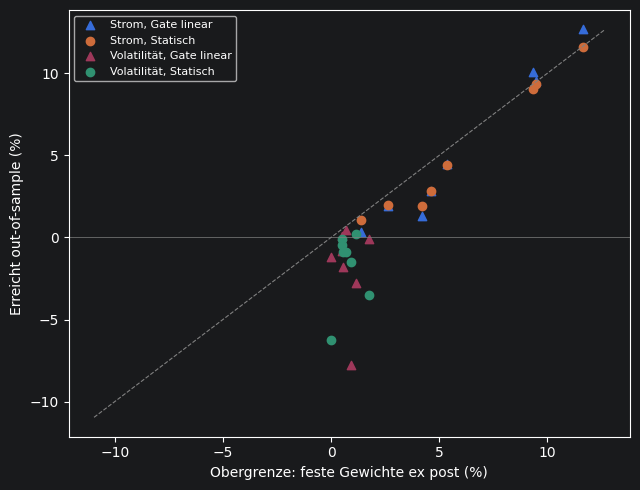

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for (dom, m), d in cmp[cmp["Methode"].isin(["Statisch", "Gate linear"])].groupby(["Domäne", "Methode"]):
    ax.scatter(d["Verbesserung %"], d["OOS %"], marker="o" if m == "Statisch" else "^", label=f"{dom}, {m}")
lo, hi = min(cmp["OOS %"].min(), 0) - 1, cmp["Verbesserung %"].max() + 1
ax.plot([lo, hi], [lo, hi], color="grey", lw=0.8, ls="--")      # Diagonale = Obergrenze voll erreicht
ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("Obergrenze: feste Gewichte ex post (%)")
ax.set_ylabel("Erreicht out-of-sample (%)")
ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig("results/oos_vs_obergrenze.png", dpi=200)
plt.show()

### Out-of-sample vs. upper bound

- **Electricity:** Points lie on the diagonal. Learned weights reach almost the full ex-post upper bound (up to ~12 %). Gate ≈ static weights, so the gain comes from mixing, not routing.
- **Volatility:** The upper bound is only 0–2 %, and out-of-sample most combinations are *worse* than the best single FM (down to −8 %). Estimation error of the weights exceeds the small potential gain (forecast combination puzzle).
- **Takeaway:** Combining pays off only when the experts are diverse (large upper bound). With redundant experts, any learned combination loses to the best single model.

In [6]:
from statistics import NormalDist

def dm_p(d, h):
    d = d[np.isfinite(d)]
    T, u, L = len(d), d - d.mean(), max(h - 1, 24)
    var = u @ u / T + 2 * sum((1 - l / (L + 1)) * (u[l:] @ u[:-l]) / T for l in range(1, L + 1))
    with np.errstate(invalid="ignore", divide="ignore"):
        return 2 * (1 - NormalDist().cdf(abs(d.mean() / np.sqrt(var / T))))

In [7]:
r = pd.read_parquet("results/forecasts/07_res.parquet")
r = r[r["pool"] == "4 FMs"].copy()
r["ape"] = 100 * np.abs(r["y"] - r["mean"]) / r["y"]
td = pd.to_datetime(r["target_date"])
feiertage = (td >= "2025-12-24") & (td < "2026-01-07")

rows = []
for periode, sub in {"alle": r, "ohne Feiertage": r[~feiertage]}.items():
    for (sid, h), g in pd.concat([sub, sub.assign(sid="alle Länder")]).groupby(["sid", "h"]):
        L = g.pivot_table(index="target_date", columns="model", values="ape")
        best = L[FMS].mean().idxmin()
        for m, ref, name in [("Statisch", best, "Statisch vs. bestes FM"),
                             ("Statisch", "Auswahl", "Statisch vs. Auswahl"),
                             ("Gate linear", "Auswahl", "Gate linear vs. Auswahl")]:
            rows.append({"Periode": periode, "Land": sid, "h": h, "Vergleich": name,
                         "Δ %": 100 * (L[m].mean() / L[ref].mean() - 1),
                         "p": dm_p((L[m] - L[ref]).to_numpy(), h)})

rob = pd.DataFrame(rows)
display(rob.pivot_table(index=["Periode", "Land", "h"], columns="Vergleich", values=["Δ %", "p"]).round(3))

p                       \
Vergleich                     Gate linear vs. Auswahl Statisch vs. Auswahl   
Periode        Land        h                                                 
alle           alle Länder 1                    0.000                0.000   
                           24                   0.008                0.002   
               de          1                    0.000                0.000   
                           24                   0.843                0.449   
               es          1                    0.000                0.000   
                           24                   0.194                0.163   
               fr          1                    0.000                0.000   
                           24                   0.005                0.006   
               it          1                    0.000                0.000   
                           24                   0.007                0.007   
ohne Feiertage alle Länder 1                    0.000                0.000   
                           24                   0.125                0.043   
               de          1                    0.000                0.000   
                           24                   0.318                0.425   
               es          1                    0.000                0.000   
                           24                   0.373                0.324   
               fr          1                    0.000                0.000   
                           24                   0.000                0.001   
               it          1                    0.000                0.000   
                           24                   0.161                0.179   

                                                                         Δ %  \
Vergleich                     Statisch vs. bestes FM Gate linear vs. Auswahl   
Periode        Land        h                                                   
alle           alle Länder 1                   0.000                 -11.781   
                           24                  0.002                  -2.422   
               de          1                   0.000                  -9.695   
                           24                  0.449                  -0.360   
               es          1                   0.000                 -10.058   
                           24                  0.163                  -1.918   
               fr          1                   0.021                 -14.407   
                           24                  0.593                  -2.499   
               it          1                   0.000                 -12.674   
                           24                  0.007                  -4.472   
ohne Feiertage alle Länder 1                   0.000                 -11.665   
                           24                  0.043                  -1.513   
               de          1                   0.000                 -10.340   
                           24                  0.425                   2.054   
               es          1                   0.000                  -9.098   
                           24                  0.324                  -1.672   
               fr          1                   0.065                 -14.539   
                           24                  0.977                  -3.400   
               it          1                   0.000                 -12.348   
                           24                  0.179                  -2.142   

                                                                           
Vergleich                     Statisch vs. Auswahl Statisch vs. bestes FM  
Periode        Land        h                                               
alle           alle Länder 1               -11.171                -10.146  
                           24               -2.738                 -2.738  
               de          1        

### Robustness (electricity, 4 FMs)

- **h=1:** Static weights beat the best training model ("Auswahl") by 8–15 % in every country, with and without holidays (all p < 0.001).
- **h=24:** Gain is small (~2 %), only significant when pooled, and partly driven by holidays.
- **Gate vs. static:** almost identical. The gain comes from mixing, not routing.

In [8]:
rows = []
for domain, (ds, kind) in SETS.items():
    files = [p for p in (Path("results/forecasts") / ds).glob("*__*.parquet") if p.stem.split("__")[1] in FMS]
    if not files:
        continue
    fc = pd.concat([pd.read_parquet(p) for p in files])
    fc = fc[(fc["target_date"] >= EVAL_START) & (fc["target_date"] < EVAL_END)]
    for (sid, h), g in fc.groupby(["sid", "h"]):
        M = g.pivot_table(index="origin", columns="model", values="mean").dropna()
        ly = np.log(g.groupby("origin")["y"].first().reindex(M.index).to_numpy())
        LF = np.log(M.to_numpy())
        common = ly - LF.mean(1)                  # Fehler des FM-Mittels (alle gleich)
        spec = LF - LF.mean(1, keepdims=True)     # Abweichung jedes FMs vom Mittel
        rows.append({"Domäne": domain, "Serie": sid, "h": h,
                     "gemeinsamer Fehler %": 100 * common.std(),
                     "Uneinigkeit FMs %": 100 * spec.std(),
                     "Anteil modellspezifisch %": 100 * spec.var() / (spec.var() + common.var())})

dec = pd.DataFrame(rows)
display(dec.groupby(["Domäne", "h"])[["gemeinsamer Fehler %", "Uneinigkeit FMs %", "Anteil modellspezifisch %"]].mean().round(2))

gemeinsamer Fehler %  Uneinigkeit FMs %  \
Domäne                  h                                             
Strom                   1                   0.99               0.67   
                        24                  5.03               2.50   
Volatilität             1                  57.82               9.93   
                        24                 81.22              18.76   
Volatilität BTC/ETH/SOL 1                  59.55               7.83   
                        24                 83.61              14.03   

                            Anteil modellspezifisch %  
Domäne                  h                              
Strom                   1                       31.56  
                        24                      20.07  
Volatilität             1                        2.74  
                        24                       4.81  
Volatilität BTC/ETH/SOL 1                        1.70  
                        24                       2.76

### Why combining fails for volatility

- Error = **common part** (error of the FM average, shared by all models) + **model-specific part** (disagreement between FMs). Mixing can only reduce the model-specific part.
- **Volatility:** FMs disagree *more* than for electricity (8–19 % vs. 0.7–2.5 %), but the common error is huge (60–80 %). The model-specific share is only 2–5 %.
- **Electricity:** small common error (1–5 %), model-specific share 20–32 %, so mixing gains ~3–10 %.
- **Takeaway:** Combining fails for volatility not because the FMs are identical, but because unpredictable shocks dominate the error.

In [9]:
def main_table(files, pool="4 FMs"):
    # files: {Domäne: (res-Datei, Loss)}. Haupttest = Gate linear vs. Auswahl, Holm-korrigiert
    rows = []
    for domain, (fname, kind) in files.items():
        r = pd.read_parquet(Path("results/forecasts") / fname)
        r = r[r["pool"] == pool].copy()
        r["l"] = loss(kind, r["y"].to_numpy(), r["mean"].to_numpy())
        for h, g in r.groupby("h"):
            L = g.pivot_table(index="target_date", columns="model", values="l")
            for m, ref, typ in [("Gate linear", "Auswahl", "Haupttest"),
                                ("Gate linear", "Statisch", "Ablation"),
                                ("Statisch", "Auswahl", "Ablation")]:
                rows.append({"Domäne": domain, "h": h, "Vergleich": f"{m} vs. {ref}", "Typ": typ,
                             "Δ %": 100 * (L[m].mean() / L[ref].mean() - 1),
                             "p": dm_p((L[m] - L[ref]).to_numpy(), h)})
    out = pd.DataFrame(rows)
    ht = out["Typ"] == "Haupttest"
    p = out.loc[ht, "p"].to_numpy()
    o, k = np.argsort(p), len(p)
    holm = np.empty(k)
    holm[o] = np.minimum(1, np.maximum.accumulate((k - np.arange(k)) * p[o]))
    out.loc[ht, "p Holm"] = holm
    return out


display(main_table({"Volatilität": ("06_res.parquet", "qlike"), "Strom": ("07_res.parquet", "ape")}).round(3))

,Domäne,h,Vergleich,Typ,Δ %,p,p Holm
0,Volatilität,1,Gate linear vs. Auswahl,Haupttest,-0.659,0.473,0.945
1,Volatilität,1,Gate linear vs. Statisch,Ablation,1.552,0.218,NaN
2,Volatilität,1,Statisch vs. Auswahl,Ablation,-2.177,0.273,NaN
3,Volatilität,24,Gate linear vs. Auswahl,Haupttest,0.822,0.523,0.945
4,Volatilität,24,Gate linear vs. Statisch,Ablation,-1.977,0.537,NaN
5,Volatilität,24,Statisch vs. Auswahl,Ablation,2.855,0.468,NaN
6,Strom,1,Gate linear vs. Auswahl,Haupttest,-11.781,0.000,0.000
7,Strom,1,Gate linear vs. Statisch,Ablation,-0.687,0.000,NaN
8,Strom,1,Statisch vs. Auswahl,Ablation,-11.171,0.000,NaN
9,Strom,24,Gate linear vs. Auswahl,Haupttest,-2.422,0.008,0.024


### Main result (Gate linear vs. best training model, Holm-corrected)

- **Electricity:** the gateway beats the best single model by **11.8 %** (h=1) and **2.4 %** (h=24), both significant after Holm correction (p < 0.001, p = 0.024).
- **Volatility:** no significant difference (−0.7 % / +0.8 %, p_Holm = 0.95).
- **Ablation gate vs. static:** input-dependent weights add at most 0.7 % (electricity h=1). The gateway essentially learns fixed weights.

In [10]:
from pipeline import common as PC, features as F, combine as cb

DS, SIDS = "binance_1h_neu", ["PAXGUSDT", "EURUSDT", "XRPUSDT", "BNBUSDT"]
daily = {s: pd.read_parquet(Path("data") / DS / f"{s}_daily.parquet") for s in SIDS}

def raw_features(d, lags=24):                                     # wie in 06
    lrv, norm = np.log(d["rv"]), np.log(d["rv"].rolling(7 * 24).mean())
    f = pd.DataFrame({f"raw_{i}": lrv.shift(i) - norm for i in range(lags)})
    f["scale"] = d["rv"].rolling(22 * 24).mean()
    return f

daily_feat = pd.concat({s: raw_features(daily[s]) for s in SIDS}, names=["sid", "origin"])
fcv = pd.concat([pd.read_parquet(Path("results/forecasts") / DS / f"{s}__{m}.parquet") for s in SIDS for m in FMS])
cfg = F.FeatureConfig(FMS, SIDS, groups=["market", "disagree"], calendar=[])
df, groups = F.build_panel(F.add_recent(fcv, cfg), daily_feat, 1, cfg)
P = cb.Panel(df, 1, FMS, {("raw" if g == "market" else g): v for g, v in groups.items()})
train = P.take(np.asarray(P.td < pd.Timestamp("2025-11-01")))

# 1) Numerik: nicht-endliche Werte im Training?
print("nicht-endlich  X:", int((~np.isfinite(train.X.to_numpy())).sum()),
      "| mean:", int((~np.isfinite(train.mean)).sum()), "| Q:", int((~np.isfinite(train.Q)).sum()))

# 2) Wird der Trainings-Loss von wenigen Stunden dominiert?
Lq = PC.qlike(train.y[:, None], train.mean)
top = Lq.mean(1) >= np.quantile(Lq.mean(1), 0.99)
display(pd.DataFrame({"QLIKE alle": Lq.mean(0), "QLIKE ohne Top 1 %": Lq[~top].mean(0),
                      "Anteil Top 1 % am Loss %": 100 * Lq[top].sum(0) / Lq.sum(0)}, index=FMS).round(3))
print("Top-1-%-Stunden nach Monat:\n", pd.Series(train.td[top].to_period("M")).value_counts().head())

# 3) Statisch mit und ohne diese Stunden
for name, mask in [("alle Stunden", np.ones(len(train), bool)), ("ohne Top 1 %", ~top)]:
    Pm = train.take(mask)
    print(f"Statisch, {name}:", dict(zip(FMS, cb.Gate(groups=()).fit(Pm).weights(Pm)[0].round(3))))

# 4) Bewegt sich das lineare Gate überhaupt?
eq = np.full((len(train), len(FMS)), 1 / len(FMS))
for lam in [1e-4, 1e-2, 1.0]:
    c = cb.Gate(lam=lam).fit(train)
    w = c.weights(train)
    print(f"λ={lam}: Loss Start {cb.comb_loss(eq, train):.4f} → nach Fit {cb.comb_loss(w, train):.4f}"
          f" | Gewichte Streuung {w.std(0).round(3)} | max |W| {np.abs(c.coef().to_numpy()).max():.3f}")

nicht-endlich  X: 0 | mean: 0 | Q: 0


,QLIKE alle,QLIKE ohne Top 1 %,Anteil Top 1 % am Loss %
Chronos-2-full,0.438,0.153,65.350
TimesFM-2.5,0.484,0.150,69.317
TiRex,0.446,0.149,66.890
FlowState,0.509,0.154,69.987


Top-1-%-Stunden nach Monat:
 target_date
2025-08    44
2025-10    40
2025-01    37
2025-09    34
2025-07    33
Freq: M, Name: count, dtype: int64


/Users/sebastianjung/Documents/HSG/HS 26/BP/Learning_to_Forecast_Time-Series_with_Multiple_Experts/src/pipeline/combine.py:67: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  return torch.as_tensor(np.asarray(a, dtype=float), dtype=DTYPE)


Statisch, alle Stunden: {'Chronos-2-full': np.float64(0.0), 'TimesFM-2.5': np.float64(0.334), 'TiRex': np.float64(0.666), 'FlowState': np.float64(0.0)}
Statisch, ohne Top 1 %: {'Chronos-2-full': np.float64(0.005), 'TimesFM-2.5': np.float64(0.376), 'TiRex': np.float64(0.34), 'FlowState': np.float64(0.279)}
λ=0.0001: Loss Start 96775233757.6337 → nach Fit 0.8393 | Gewichte Streuung [0.039 0.013 0.013 0.013] | max |W| 0.175
λ=0.01: Loss Start 96775233757.6337 → nach Fit 0.8393 | Gewichte Streuung [0.039 0.013 0.013 0.013] | max |W| 0.175
λ=1.0: Loss Start 96775233757.6337 → nach Fit 0.8393 | Gewichte Streuung [0.039 0.013 0.013 0.013] | max |W| 0.175


### Diagnosis: why combinations fail out-of-sample for volatility

- **Extreme hours dominate training:** the worst 1 % of hours account for 65–70 % of the training loss for every FM. Without them, all four FMs are almost equally good (QLIKE 0.149–0.154).
- **Static weights depend on these hours:** with them TiRex 67 % / TimesFM 33 %, without them TimesFM 38 % / TiRex 34 % / FlowState 28 %. Weights estimated from ~1 % of the data are unstable and lose out-of-sample.
- **Linear gate:** the loss at equal weights is ~10¹¹ because some expert quantiles are extremely large in a few hours. The optimizer only learns to avoid that expert and then stops; results are identical for every λ. No NaN/inf values were found.

In [15]:
rows = []
for ds in ["binance_1h_neu", "binance_1h", "strom_1h"]:
    for p in (Path("results/forecasts") / ds).glob("*__*.parquet"):
        sid, m = p.stem.split("__")
        f = pd.read_parquet(p)
        Q = f[PC.QCOLS].to_numpy()
        s = np.log(Q[:, -1] / Q[:, 10])                   # log(q0.99 / Median)
        rows.append({"Datensatz": ds, "Serie": sid, "Modell": m, "max": s.max(),
                     "Zeilen > e^5": int((s > 5).sum()), "Anteil %": 100 * (s > 5).mean()})

chk = pd.DataFrame(rows)
display(chk.pivot_table(index=["Datensatz", "Serie"], columns="Modell", values="Zeilen > e^5", aggfunc="sum"))
display(chk.pivot_table(index=["Datensatz", "Serie"], columns="Modell", values="max").round(1))

Modell                   Chronos-2-full  EWMA  FlowState  GARCH  HAR      RW  \
Datensatz      Serie                                                           
binance_1h     BTCUSDT             57.0   0.0        NaN    0.0  0.0     0.0   
               ETHUSDT             76.0   0.0        NaN    0.0  0.0     0.0   
               SOLUSDT             75.0   0.0        NaN    0.0  0.0     0.0   
binance_1h_neu BNBUSDT             31.0   NaN        1.0    0.0  0.0     0.0   
               EURUSDT            157.0   NaN        2.0  192.0  0.0     0.0   
               PAXGUSDT            73.0   NaN        1.0    0.0  0.0  1683.0   
               XRPUSDT             58.0   NaN        1.0    0.0  0.0     0.0   
strom_1h       de                   0.0   NaN        0.0    NaN  NaN     0.0   
               es                   0.0   NaN        0.0    NaN  NaN     0.0   
               fr                   0.0   NaN        0.0    NaN  NaN     0.0   
               it                   0.0   NaN        0.0    NaN  NaN     0.0   

Modell                   SNaive  SeasReg  TiRex  TimesFM-2.5  
Datensatz      Serie                                          
binance_1h     BTCUSDT      NaN      NaN    NaN          1.0  
               ETHUSDT      NaN      NaN    NaN          2.0  
               SOLUSDT      NaN      NaN    NaN          0.0  
binance_1h_neu BNBUSDT      NaN      NaN    6.0          1.0  
               EURUSDT      NaN      NaN   13.0          0.0  
               PAXGUSDT     NaN      NaN   22.0          2.0  
               XRPUSDT      NaN      NaN    5.0          3.0  
strom_1h       de           0.0      0.0    0.0          0.0  
               es           0.0      0.0    0.0          0.0  
               fr           0.0      0.0    0.0          0.0  
               it           0.0      0.0    0.0          0.0

Modell                   Chronos-2-full  EWMA  FlowState  GARCH  HAR   RW  \
Datensatz      Serie                                                        
binance_1h     BTCUSDT             17.2   3.5        NaN    2.8  2.9  3.5   
               ETHUSDT             24.9   3.3        NaN    2.7  3.0  3.3   
               SOLUSDT             16.2   3.2        NaN    2.5  2.9  3.1   
binance_1h_neu BNBUSDT             17.0   NaN        5.2    2.4  2.9  3.4   
               EURUSDT             28.5   NaN        5.6    7.0  3.1  3.3   
               PAXGUSDT            13.4   NaN        5.9    2.7  3.1  5.4   
               XRPUSDT             42.5   NaN        5.9    2.5  3.1  3.7   
strom_1h       de                   1.3   NaN        0.3    NaN  NaN  0.4   
               es                   0.7   NaN        0.2    NaN  NaN  0.3   
               fr                   1.3   NaN        0.3    NaN  NaN  0.3   
               it                   0.8   NaN        0.3    NaN  NaN  0.4   

Modell                   SNaive  SeasReg  TiRex  TimesFM-2.5  
Datensatz      Serie                                          
binance_1h     BTCUSDT      NaN      NaN    NaN          5.1  
               ETHUSDT      NaN      NaN    NaN          5.6  
               SOLUSDT      NaN      NaN    NaN          5.0  
binance_1h_neu BNBUSDT      NaN      NaN    6.9          5.8  
               EURUSDT      NaN      NaN   13.4          4.7  
               PAXGUSDT     NaN      NaN    8.6          5.3  
               XRPUSDT      NaN      NaN   11.3          5.4  
strom_1h       de           0.3      0.2    0.6          0.3  
               es           0.3      0.2    0.7          0.3  
               fr           0.4      0.2    0.4          0.3  
               it           0.4      0.3    0.8          0.4

### Quantile check across all datasets

- **Chronos-2 produces absurd upper quantiles on all 7 volatility series** (31–157 forecasts per series, q0.99 up to e⁴² × median), including BTC/ETH/SOL. TiRex shows the same issue on a smaller scale (≤ 22 rows, up to e¹³).
- **Electricity is unaffected** (all models below e^1.3).
- Wide but plausible distributions (RW on PAXG, GARCH on EUR, max e^5–e^7) are not errors.
- **Fix:** cap quantiles at median · e^±8 and recompute the mean; rerun the volatility combinations (06, 04/05) and the analyses in 08.